# TP 1 : Estimation de densité

## Exercice 1: Données simulées

In [24]:
import numpy as np
import matplotlib.pyplot as plt

### 1. Construction des données simulées


In [25]:
np.random.seed(42)
Y = np.random.normal(-1.5, np.sqrt(2),50)
Z = np.random.uniform(size=50)
X = np.concatenate((Y, Z))

### 2. Estimation de la densité f de X

(a) Tracé de l'histogramme de X

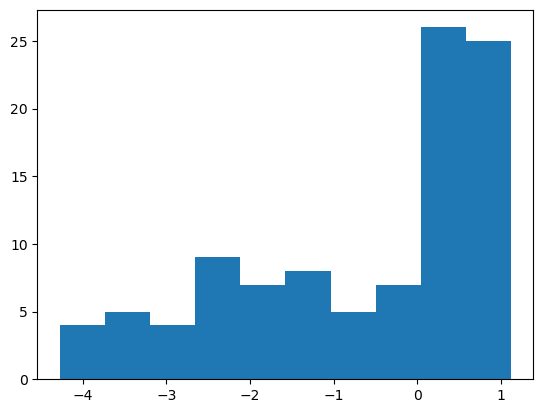

In [26]:
plt.hist(X)
plt.savefig('histogramme_X.png')
plt.show()

(b) Définition des noyaux

In [27]:
def rectangular_kernel(u) :
    return(0.5*(np.abs(u) < 1))

def gaussian_kernel(u):
    return((1/np.sqrt(2*np.pi))*np.exp(-u**2/2))


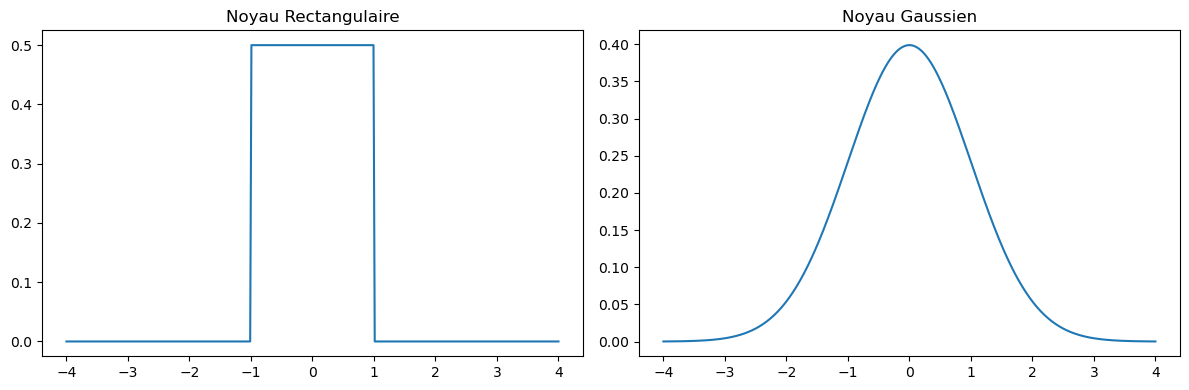

In [28]:
# Tracé des noyaux   
u = np.linspace(-4,4,400)
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(u,rectangular_kernel(u))
ax[1].plot(u,gaussian_kernel(u))
ax[0].set_title("Noyau Rectangulaire")
ax[1].set_title("Noyau Gaussien")
plt.tight_layout()
plt.savefig('illustration_noyaux.png', dpi=300)
plt.show()

h de silverman=0.53


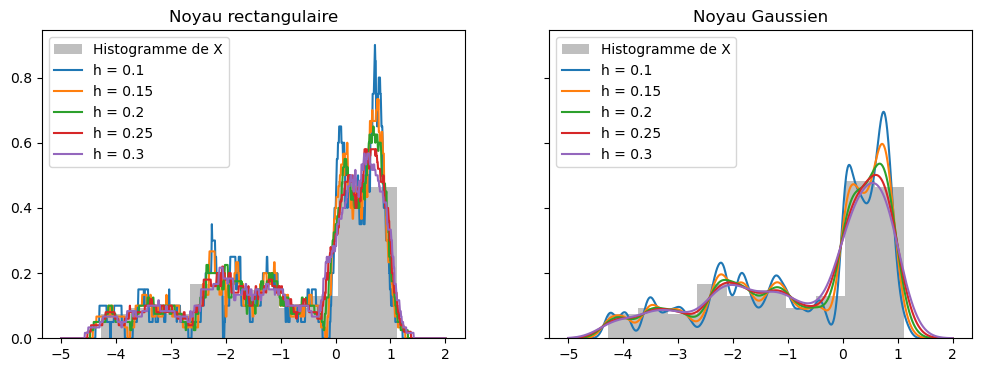

In [29]:
# définition de l'estimateur à noyau

def kde(t,X,h,kernel):
    try:
        n = len(t)
    except:
        t = np.array([t])
        n = 1
    Y = np.zeros(n)
    for i in range(n):
        Y[i] = np.mean(kernel((t[i] - X)/h)/h)
    return(Y)
n=len(X)
ecart_type=np.std(X)
IQR= np.percentile(X,75) -  np.percentile(X,25)
h_silverman= 0.9*np.min([ecart_type,(IQR/1.34)])*(n**(-1/5))
print(f"h de silverman={h_silverman:.2f}")    
t = np.linspace(-5,2,1000)
h_values = np.linspace(0.1,0.3,5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1.hist(X, density=True, alpha=0.5, color='gray', label="Histogramme de X")
for h in h_values:
    ax1.plot(t, kde(t,X,h,rectangular_kernel), label=f"h = {h}")
ax1.set_title("Noyau rectangulaire")
ax1.legend()
ax2.hist(X, density=True, alpha=0.5, color='gray', label="Histogramme de X")
for h in h_values:
    ax2.plot(t, kde(t,X,h,gaussian_kernel), label=f"h = {h}")
ax2.set_title("Noyau Gaussien")
ax2.legend()
plt.savefig('kde_non_opt.png')
plt.show()

On a : $\operatorname{CV}(h) = \int \hat{f_h^2} - \frac{2}{n}\sum_{i=1}^n \hat{f}_{h,-i}(X_i)$.

Pour le calcul de l'intégrale $ I = \int \hat{f_{h}^2} $ nous allons utiliser la méthode des trapèzes.

In [31]:
# Implémentation de la méthode des trapèzes pour le premier terme

def trapeze(m,f,X):
    t = np.linspace(np.min(X),np.max(X),m)
    integral = 0
    for i in range(m-1):
        integral += (t[i+1] - t[i])*(f(t[i+1]) + f(t[i]))/2
    return(integral)

In [32]:
# fonction pour le calcul du deuxième terme 

def leave_one_out(X,h,kernel):
    n = len(X)
    D = X[:, None] - X[None, :]    
    K = kernel(D/h)/ h  
    
    np.fill_diagonal(K, 0)
    f_loo = np.sum(K, axis=1) / (n - 1)   
    return(-2 * np.mean(f_loo))

# fonction validation croisée

def CV(h,X,kernel):
    first_term = trapeze(10001,lambda t:kde(t,X,h,kernel)**2,X)
    second_term = leave_one_out(X,h,kernel)
    return(first_term + second_term)

0.15


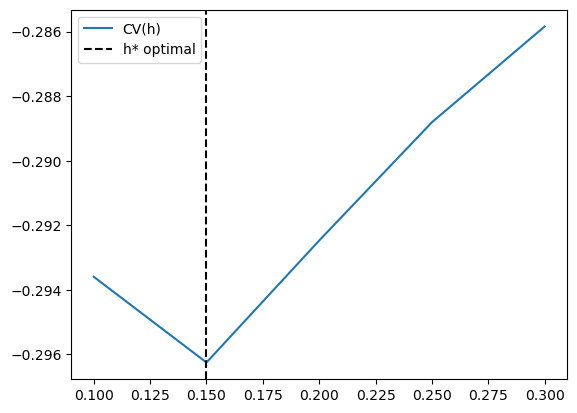

In [33]:
CV_values_gaussian = [CV(h,X,gaussian_kernel) for h in h_values]
CV_values_rectangular = [CV(h,X,rectangular_kernel) for h in h_values]
h_opt_gaussian = h_values[np.argmin(CV_values_gaussian)]
h_opt_rectangular = h_values[np.argmin(CV_values_rectangular)]
print(h_opt_gaussian)
plt.plot(h_values,CV_values_gaussian,label='CV(h)')
plt.axvline(x=h_opt_gaussian,color='black',linestyle='dashed',label='h* optimal')
plt.legend()
plt.savefig('validation_croisée.png')
plt.show()

Ainsi, en utilisant la validation croisée on a l'estimateur optimal suivant :

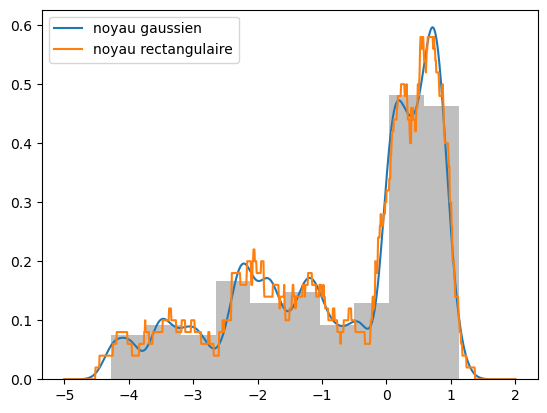

In [34]:
plt.plot(t,kde(t,X,h_opt_gaussian,gaussian_kernel), label='noyau gaussien')
plt.plot(t,kde(t,X,h_opt_rectangular,rectangular_kernel), label='noyau rectangulaire')
plt.hist(X,density=True,color='grey',alpha=0.5)
plt.legend()
plt.savefig('kde_opt')
plt.show()

## Exercice 2. Données réelles

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
# Importation de la base de données
Data= sns.load_dataset('mpg')
print(Data)

      mpg  cylinders  displacement  horsepower  weight  acceleration  \
0    18.0          8         307.0       130.0    3504          12.0   
1    15.0          8         350.0       165.0    3693          11.5   
2    18.0          8         318.0       150.0    3436          11.0   
3    16.0          8         304.0       150.0    3433          12.0   
4    17.0          8         302.0       140.0    3449          10.5   
..    ...        ...           ...         ...     ...           ...   
393  27.0          4         140.0        86.0    2790          15.6   
394  44.0          4          97.0        52.0    2130          24.6   
395  32.0          4         135.0        84.0    2295          11.6   
396  28.0          4         120.0        79.0    2625          18.6   
397  31.0          4         119.0        82.0    2720          19.4   

     model_year  origin                       name  
0            70     usa  chevrolet chevelle malibu  
1            70     usa      

In [37]:
# Extraction de la variable mpg
mpg_data=Data['mpg'].values
mpg_data = np.array(mpg_data)
print(mpg_data)

[18.  15.  18.  16.  17.  15.  14.  14.  14.  15.  15.  14.  15.  14.
 24.  22.  18.  21.  27.  26.  25.  24.  25.  26.  21.  10.  10.  11.
  9.  27.  28.  25.  25.  19.  16.  17.  19.  18.  14.  14.  14.  14.
 12.  13.  13.  18.  22.  19.  18.  23.  28.  30.  30.  31.  35.  27.
 26.  24.  25.  23.  20.  21.  13.  14.  15.  14.  17.  11.  13.  12.
 13.  19.  15.  13.  13.  14.  18.  22.  21.  26.  22.  28.  23.  28.
 27.  13.  14.  13.  14.  15.  12.  13.  13.  14.  13.  12.  13.  18.
 16.  18.  18.  23.  26.  11.  12.  13.  12.  18.  20.  21.  22.  18.
 19.  21.  26.  15.  16.  29.  24.  20.  19.  15.  24.  20.  11.  20.
 21.  19.  15.  31.  26.  32.  25.  16.  16.  18.  16.  13.  14.  14.
 14.  29.  26.  26.  31.  32.  28.  24.  26.  24.  26.  31.  19.  18.
 15.  15.  16.  15.  16.  14.  17.  16.  15.  18.  21.  20.  13.  29.
 23.  20.  23.  24.  25.  24.  18.  29.  19.  23.  23.  22.  25.  33.
 28.  25.  25.  26.  27.  17.5 16.  15.5 14.5 22.  22.  24.  22.5 29.
 24.5 29.  33.  20. 

h optimal sélectionné par validation croisée : 1.864


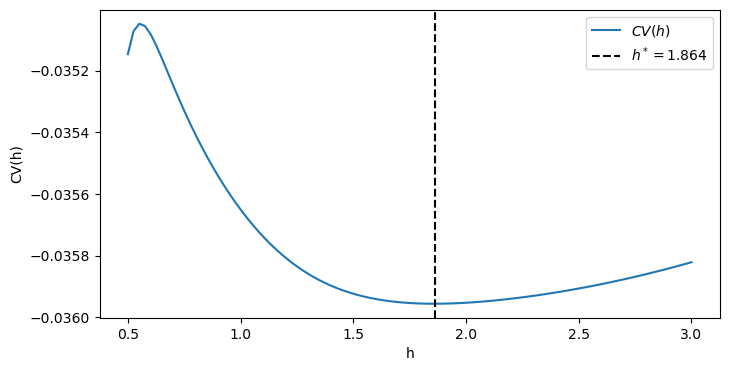

In [38]:
h_values = np.linspace(0.5, 3, 100)
CV_values = [CV(h,mpg_data,gaussian_kernel) for h in h_values]
h_opt = h_values[np.argmin(CV_values)]
print(f"h optimal sélectionné par validation croisée : {h_opt:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(h_values, CV_values, label=r"$CV(h)$")
plt.axvline(h_opt, color="black", linestyle="--", label=f"$h^* = {h_opt:.3f}$")   
plt.xlabel("h")
plt.ylabel("CV(h)")
plt.legend()
plt.show()

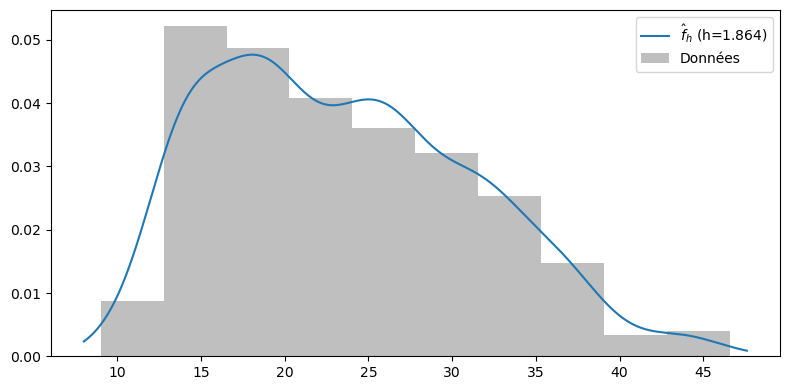

In [39]:
mpg_grid = np.linspace(mpg_data.min() - 1, mpg_data.max() + 1, 1000)
plt.figure(figsize=(8, 4))
plt.plot(mpg_grid, kde(mpg_grid, mpg_data, h_opt,gaussian_kernel), label=rf"$\hat{{f}}_{{h}}$ (h={h_opt:.3f})")
plt.hist(mpg_data, density=True, alpha=0.5, color="gray", label="Données")
plt.legend()
plt.tight_layout()
plt.show()